In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.metrics import confusion_matrix, classification_report
import warnings
warnings.filterwarnings("ignore")

# Cargar la base de datos desde GitHub (con respaldo local)
url = "https://raw.githubusercontent.com/JoseRaulCastro/EBAC/main/recursos_humanos.csv"
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv("recursos_humanos.csv")

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [12]:
# Re-codificar variables categóricas 'sales' y 'salary'
df_encoded = pd.get_dummies(df, columns=["sales", "salary"], dtype=int)

X = df_encoded.drop(columns=["left"]).values
y = df_encoded["left"].values

# División en entrenamiento y prueba (misma proporción y semilla del código base)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

print("Grupo de entrenamiento:", X_train.shape, y_train.shape)
print("Grupo de prueba:", X_test.shape, y_test.shape)

Grupo de entrenamiento: (11999, 20) (11999,)
Grupo de prueba: (3000, 20) (3000,)


Matriz de confusión (Kernel Lineal):
 [[2149  138]
 [ 522  191]]


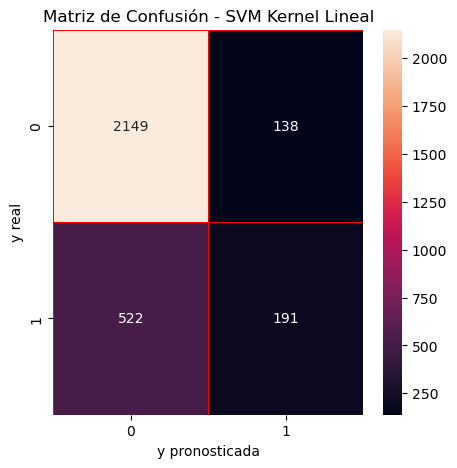

              precision    recall  f1-score   support

           0       0.80      0.94      0.87      2287
           1       0.58      0.27      0.37       713

    accuracy                           0.78      3000
   macro avg       0.69      0.60      0.62      3000
weighted avg       0.75      0.78      0.75      3000



In [13]:
clf_linear = svm.SVC(kernel="linear", random_state=4)
clf_linear.fit(X_train, y_train)
yhat_linear = clf_linear.predict(X_test)

cm_linear = confusion_matrix(y_test, yhat_linear)
print("Matriz de confusión (Kernel Lineal):\n", cm_linear)

f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm_linear, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("Matriz de Confusión - SVM Kernel Lineal")
plt.show()

print(classification_report(y_test, yhat_linear))

Matriz de confusión (Kernel Polinomial):
 [[2287    0]
 [ 713    0]]


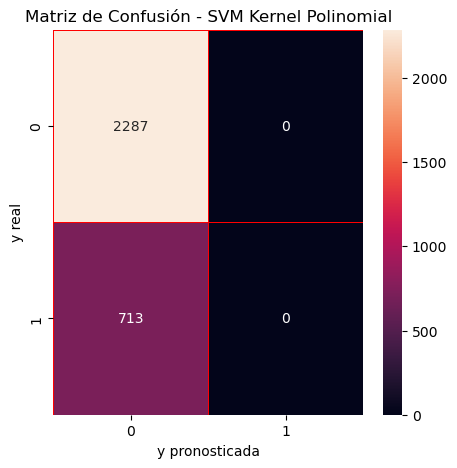

              precision    recall  f1-score   support

           0       0.76      1.00      0.87      2287
           1       0.00      0.00      0.00       713

    accuracy                           0.76      3000
   macro avg       0.38      0.50      0.43      3000
weighted avg       0.58      0.76      0.66      3000



In [14]:
clf_poly = svm.SVC(kernel="poly", random_state=4)
clf_poly.fit(X_train, y_train)
yhat_poly = clf_poly.predict(X_test)

cm_poly = confusion_matrix(y_test, yhat_poly)
print("Matriz de confusión (Kernel Polinomial):\n", cm_poly)

f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm_poly, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("Matriz de Confusión - SVM Kernel Polinomial")
plt.show()

print(classification_report(y_test, yhat_poly))

Matriz de confusión (Kernel RBF):
 [[2287    0]
 [ 669   44]]


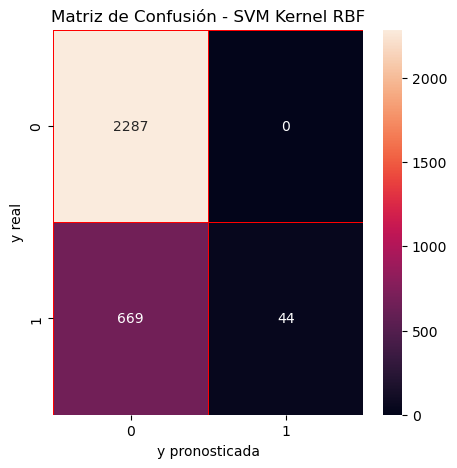

              precision    recall  f1-score   support

           0       0.77      1.00      0.87      2287
           1       1.00      0.06      0.12       713

    accuracy                           0.78      3000
   macro avg       0.89      0.53      0.49      3000
weighted avg       0.83      0.78      0.69      3000



In [15]:
clf_rbf = svm.SVC(kernel="rbf", random_state=4)
clf_rbf.fit(X_train, y_train)
yhat_rbf = clf_rbf.predict(X_test)

cm_rbf = confusion_matrix(y_test, yhat_rbf)
print("Matriz de confusión (Kernel RBF):\n", cm_rbf)

f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm_rbf, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("Matriz de Confusión - SVM Kernel RBF")
plt.show()

print(classification_report(y_test, yhat_rbf))

Matriz de confusión (Kernel Sigmoide):
 [[1885  402]
 [ 507  206]]


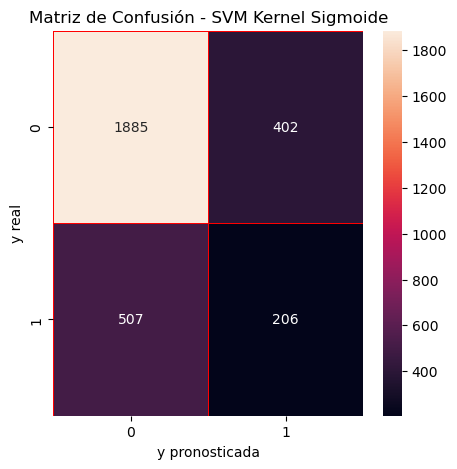

              precision    recall  f1-score   support

           0       0.79      0.82      0.81      2287
           1       0.34      0.29      0.31       713

    accuracy                           0.70      3000
   macro avg       0.56      0.56      0.56      3000
weighted avg       0.68      0.70      0.69      3000



In [16]:
clf_sigmoid = svm.SVC(kernel="sigmoid", random_state=4)
clf_sigmoid.fit(X_train, y_train)
yhat_sigmoid = clf_sigmoid.predict(X_test)

cm_sigmoid = confusion_matrix(y_test, yhat_sigmoid)
print("Matriz de confusión (Kernel Sigmoide):\n", cm_sigmoid)

f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm_sigmoid, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("Matriz de Confusión - SVM Kernel Sigmoide")
plt.show()

print(classification_report(y_test, yhat_sigmoid))

In [17]:
# Indicadores del empleado:
# satisfaction_level=0.5, last_evaluation=0.75, number_project=4, average_montly_hours=200,
# time_spend_company=4, Work_accident=0, promotion_last_5years=0, sales='sales', salary='medium'
feature_names = df_encoded.drop(columns=["left"]).columns
empleado = pd.DataFrame([{col: 0 for col in feature_names}])

empleado["satisfaction_level"] = 0.5
empleado["last_evaluation"] = 0.75
empleado["number_project"] = 4
empleado["average_montly_hours"] = 200
empleado["time_spend_company"] = 4
empleado["Work_accident"] = 0
empleado["promotion_last_5years"] = 0
if "sales_sales" in empleado.columns:
    empleado["sales_sales"] = 1
if "salary_medium" in empleado.columns:
    empleado["salary_medium"] = 1

modelos = {
    "linear": clf_linear,
    "poly": clf_poly,
    "rbf": clf_rbf,
    "sigmoid": clf_sigmoid
}

for nombre, modelo in modelos.items():
    pred = modelo.predict(empleado.values)[0]
    estado = "Deja la empresa (1)" if pred == 1 else "Permanece en la empresa (0)"
    print(f"Kernel {nombre:8s} -> Pronóstico left = {pred} ({estado})")

Kernel linear   -> Pronóstico left = 0 (Permanece en la empresa (0))
Kernel poly     -> Pronóstico left = 0 (Permanece en la empresa (0))
Kernel rbf      -> Pronóstico left = 0 (Permanece en la empresa (0))
Kernel sigmoid  -> Pronóstico left = 0 (Permanece en la empresa (0))
